<a href="https://colab.research.google.com/github/JohnDoheny/csfcj/blob/main/Data%20%26%20Machine%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [71]:
import pandas as pd



In [72]:
#load the data
spd=pd.read_csv("Student_performance_data(in).csv")

In [73]:
#look at first 10 entries
spd.head(10)

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061
5,1006,18,0,0,1,8.191219,0,0,1,1,0,0,0,3.084184
6,1007,15,0,1,1,15.601680,10,0,3,0,1,0,0,2.748237
7,1008,15,1,1,4,15.424496,22,1,1,1,0,0,0,1.360143
8,1009,17,0,0,0,4.562008,1,0,2,0,1,0,1,2.896819
9,1010,16,1,0,1,18.444466,0,0,3,1,0,0,0,3.573474


In [74]:
spd.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000


In [75]:
gpa=spd["GPA"]

In [76]:
print(gpa)

0       2.929196
1       3.042915
2       0.112602
3       2.054218
4       1.288061
          ...   
2387    3.455509
2388    3.279150
2389    1.142333
2390    1.803297
2391    2.140014
Name: GPA, Length: 2392, dtype: float64


In [77]:
#find min & max
print("Minimum GPA: ", gpa.min())
print("Maximum GPA: ", gpa.max())
print("Average GPA: ", gpa.mean())

Minimum GPA:  0.0
Maximum GPA:  4.0
Average GPA:  1.9061863027224077


<Axes: >

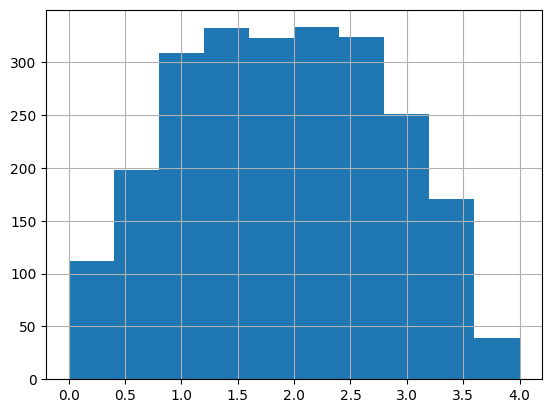

In [78]:
gpa.hist()

In [79]:
spd["Gender"].value_counts()

,count
Gender,
1,1222
0,1170


In [80]:
spd['ParentalEducation'].value_counts()

,count
ParentalEducation,
2,934
1,728
3,367
0,243
4,120


In [81]:
display(spd.groupby("ParentalEducation")["GPA"].mean().round(2))

,GPA
ParentalEducation,
0,1.89
1,1.94
2,1.93
3,1.81
4,1.82


In [82]:
#Create groups based on weekly study time
spd["StudyGroup"] = '10 hours or more'

In [83]:
spd.loc[spd["StudyTimeWeekly"]<10, "StudyGroup"]='Under 10 Hours'

In [84]:
spd.groupby("StudyGroup")["GPA"].mean()

,GPA
StudyGroup,
10 hours or more,2.048585
Under 10 Hours,1.773450


In [85]:
display(spd.groupby("Ethnicity")["GPA"].mean().round(2))

,GPA
Ethnicity,
0,1.88
1,1.95
2,1.92
3,1.95


In [86]:
display(spd.groupby("ParentalSupport")["GPA"].mean().round(2))

,GPA
ParentalSupport,
0,1.54
1,1.76
2,1.88
3,2.04
4,2.19


In [87]:
display(spd.groupby("Age")["GPA"].mean().round(2))

,GPA
Age,
15,1.90
16,1.91
17,1.93
18,1.89


In [88]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [89]:
spd["PassFail"]= (spd["GPA"]>=2.0).astype(int)


In [90]:
spd = spd[["StudyTimeWeekly", "Absences", "Age", "PassFail"]]
spd.head()

,StudyTimeWeekly,Absences,Age,PassFail
0,19.833723,7,17,1
1,15.408756,0,18,1
2,4.210570,26,15,0
3,10.028829,14,17,1
4,4.672495,17,17,0


In [91]:
spd.describe()

,StudyTimeWeekly,Absences,Age,PassFail
count,2392.000000,2392.000000,2392.000000,2392.000000
mean,9.771992,14.541388,16.468645,0.467391
std,5.652774,8.467417,1.123798,0.499040
min,0.001057,0.000000,15.000000,0.000000
25%,5.043079,7.000000,15.000000,0.000000
50%,9.705363,15.000000,16.000000,0.000000
75%,14.408410,22.000000,17.000000,1.000000
max,19.978094,29.000000,18.000000,1.000000


In [97]:
#Historical inputs
x = spd[["StudyTimeWeekly", "Absences", "Age"]]
#Historical outcome
y = spd["PassFail"]
#not give it everything, as it will answer its problems. When it goes live, give it all the data


In [114]:
#Splits data into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=23)

In [115]:
#Creates the Decision tree and train it using the training data
my_model= DecisionTreeClassifier()
my_model.fit(X_train, y_train)

DecisionTreeClassifier()

In [116]:
#Predict Pass/Fail for the test data
y_pred= my_model.predict(X_test)

In [117]:
#Calculate the proportion of the test predictions that were correct
accuracy_score(y_test, y_pred)

0.8810020876826722

In [118]:
confusion_matrix(y_test,y_pred)

array([[216,  29],
       [ 28, 206]])

In [130]:
study_time = float(input("Enter weekly study hours: "))
absences = int(input("Enter number of absences: "))
age = int(input("Enter student age: "))

Enter weekly study hours: 2
Enter number of absences: 0
Enter student age: 17


In [131]:
new_student = [[ study_time , absences, age]]
prediction = my_model.predict ( new_student )
if prediction[0] == 1:
  print("Predicted outcome: Pass")
else:
  print("Predicted outcome: Fail")

Predicted outcome: Pass


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
